# Survey ways to plot cross sections with OpenMC

<!-- index:description -->
Survey three ways to plot continuous-energy cross sections in OpenMC: `plot_xs()`, `calculate_cexs()`, and direct access to HDF5 data.
<!-- /index:description -->

<!-- generated:structure -->
```text
Survey ways to plot cross sections with OpenMC
├── Lithium: a candidate for tritium breeding
├── 1. `openmc.plot_xs()`
├── 2. `openmc.calculate_cexs()`
├── 3. `openmc.data.IncidentNeutron.from_hdf5()`
│   ├── Inspect `xs_data`
│   └── Extract barns from `xs_data`
├── Motivation for lithium enrichment
└── Comparison of the three plotting methods
```
<!-- /generated:structure -->

Plot triton-production cross sections (MT=205, (n,Xt)) of Li6 and Li7 using the same ENDF/B-VIII.1 library at 294 K. The three approaches differ mainly in how much control they give over the data and plotting.

## Lithium: a candidate for tritium breeding
D-T fusion reactors need tritium as part of the fuel mix. Tritium is scarce in nature. Tritium production is therefore critical. Lithium is a leading candidate for tritium breeding. Among other factors, the tritium-breeding potential of natural lithium depends on the isotopic abundances of Li6 and Li7 and their energy-dependent (n,Xt) cross sections. Energies of particular interest are:
- ~0.025 eV, for thermal neutrons;
- 14 MeV, for neutrons emerging from\
  D + T $\rightarrow \alpha$ (3.52 MeV) + n (14.06 MeV).

In [1]:
import openmc
import numpy as np
import matplotlib.pyplot as plt
from openmc_workbench_config import DATA_ROOT

xs_xml = DATA_ROOT / 'endf-b8.1' / 'cross_sections.xml'
openmc.config['cross_sections'] = xs_xml

# Li6: Higher (n,t) cross section at thermal neutron energies.
# Li7: 92.4% natural abundance; tritium production above ~2.5 MeV.
nuclides = ['Li6', 'Li7']

temperature_K = 294

energies_MeV = [0.025e-6, 14]

MT 205 (n,Xt) includes 
- MT 105 (n,t);
- MT 33 (n,nt).

In [2]:
mt, mt_label = 205, '(n,Xt)'
reactions = {nuclide: [mt_label] for nuclide in nuclides}

def format_ax(ax):
    for E in energies_MeV:
        ax.axvline(E, ls=':', color='k')
    ax.grid()
    ax.set(
        xscale='log',
        yscale='log',
        xlabel='Energy (MeV)',
        ylabel='Microscopic cross section (b)',
    )
    ax.legend(loc='upper left', bbox_to_anchor=(1, 1))

In [3]:
# Extract natural isotopic abundance.
openmc.data.isotopes('Li')
# The natural isotopic abundances of Li6 and Li7 are ~8% and ~92%, respectively. 

[('Li6', 0.07589), ('Li7', 0.92411)]

## 1. `openmc.plot_xs()`

The shortest route: OpenMC calculates and plots the cross sections. Matplotlib can still be used to customize the axes.

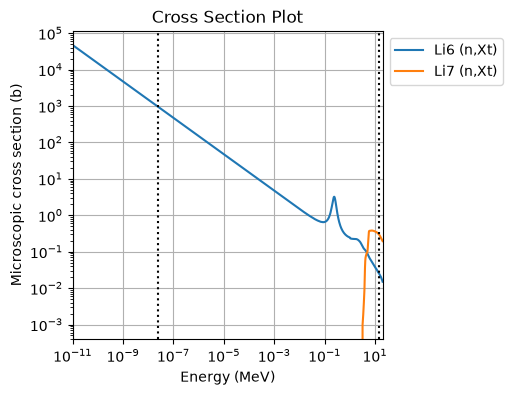

In [4]:
fig, ax = plt.subplots(figsize=(4, 4))
openmc.plot_xs(
    reactions=reactions,
    temperature=temperature_K,
    energy_axis_units='MeV',
    axis=ax,
)
format_ax(ax)

## 2. `openmc.calculate_cexs()`
Obtain the energy grid (in eV) and cross-section arrays (in barns), then plot them yourself with Matplotlib.

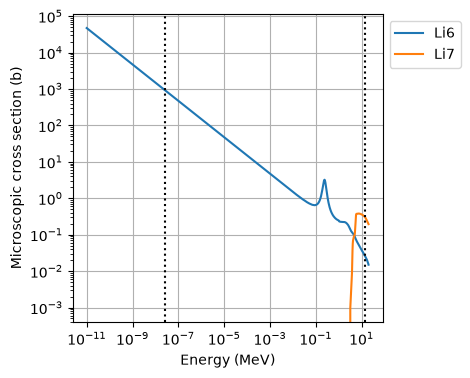

In [5]:
fig, ax = plt.subplots(figsize=(4, 4))

for nuclide, types in reactions.items():
    E, xs = openmc.plotter.calculate_cexs(
        nuclide, types, temperature=temperature_K,
    )
    ax.plot(E / 1e6, xs.squeeze(), label=nuclide)

format_ax(ax)

## 3. `openmc.data.IncidentNeutron.from_hdf5()`
Read the tabulated cross sections directly from the HDF5 library. Here, each reaction's xs is an openmc.data.Tabulated1D object. Unlike the preceding approaches, the temperature entry is selected explicitly.

Function returns an [openmc.data.Tabulated1D](https://docs.openmc.org/en/stable/pythonapi/generated/openmc.data.Tabulated1D.html) object.

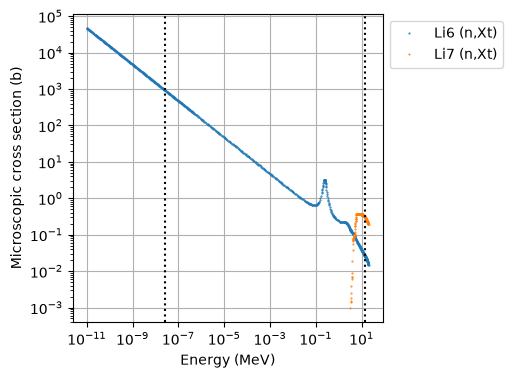

In [6]:
library = openmc.data.DataLibrary.from_xml()

xs_data = {}
fig, ax = plt.subplots(figsize=(4, 4))
for nuclide in nuclides:
    filename = library.get_by_material(nuclide)['path']
    data = openmc.data.IncidentNeutron.from_hdf5(filename)

    xs_data[nuclide] = data[mt].xs[f'{temperature_K}K']
    E = xs_data[nuclide].x
    xs = xs_data[nuclide].y
    ax.plot(E / 1e6, xs, '.', ms=1, label=f'{nuclide} {mt_label}')

format_ax(ax)

### Inspect `xs_data`
The following cells examine `xs_data` from the last iteration above (Li7):
- `interpolation` gives the interpolation codes;
- `breakpoints` marks the ends of interpolation regions.

In [7]:
xs_data['Li6'].interpolation
# That's the linear-linear interpolation scheme

array([2])

In [8]:
from openmc.data.function import INTERPOLATION_SCHEME
INTERPOLATION_SCHEME

{1: 'histogram',
 2: 'linear-linear',
 3: 'linear-log',
 4: 'log-linear',
 5: 'log-log'}

In [9]:
xs_data['Li6'].breakpoints

array([865])

### Extract barns from `xs_data`
A Tabulated1D object can be called like a function. The input energy is in eV; the returned cross section is in barns.

In [10]:
xs_data['Li6'](np.asarray(energies_MeV)*1e6)
# (X,nt) cross section (barn) for Li6 at 0.025e-6 MeV and 14 MeV.

array([9.43733919e+02, 2.60000000e-02])

In [11]:
xs_data['Li7'](np.asarray(energies_MeV)*1e6)
# (X,nt) cross section (barn) for Li7 at 0.025e-6 MeV and 14 MeV.
# In terms of tritium production at 14 MeV, Li7 is better than Li6.

array([0.      , 0.302352])

## Motivation for lithium enrichment

In [12]:
xs_data['Li6'].y.max(), xs_data['Li7'].y.max()
# The (X,nt) cross section plots for Li6 and Li7 peak at 47184.62 barn and 0.3805 barn, respectively. 
# In terms of the peak of (X,nt) cross-section curve, Li6 is better than Li7.

(np.float64(47184.62), np.float64(0.3805))

In [13]:
xs_data['Li7'].x[:5]/1e6
# The plot for (X,nt) cross section (barn) for Li7 in fact starts in the MeV range. The threshold for tritium production is high. 
# In terms of tritium production at lower energies, Li6 is better than Li7.

array([3.1454  , 3.2     , 3.3     , 3.331563, 3.4     ])

The neutron multiplication characteristics of Li6 and Li7 will be explored not in the next notebook.

## Comparison of the three plotting methods

| Method | Microscopic XS | Macroscopic XS | Main advantage |
|---|---|---|---|
| `openmc.plot_xs()` | Yes | Yes, using `openmc.Material` | Quick plotting with minimal code |
| `openmc.plotter.calculate_cexs()` | Yes | Yes, using `openmc.Material` | Access to calculated arrays for custom plotting and analysis |
| `openmc.data.IncidentNeutron.from_hdf5()` | Yes | Requires manual mixing | Direct access to tabulated nuclear data and interpolation metadata |

The first two methods support macroscopic cross sections directly, accounting for material composition and atomic number densities. The third provides microscopic cross sections for individual nuclides. Constructing macroscopic cross sections would require manual mixing,

$$
\Sigma_r(E) = \sum_i N_i \sigma_{i,r}(E).
$$

Manual mixing is generally not recommended for practical applications, but can be useful for educational exercises and verification.